# Example use of the `morse_pi` package (non-Cartesian)

## Load saved data
Plot data to ensure correct sorting

(7200, 3)
(32, 7200)


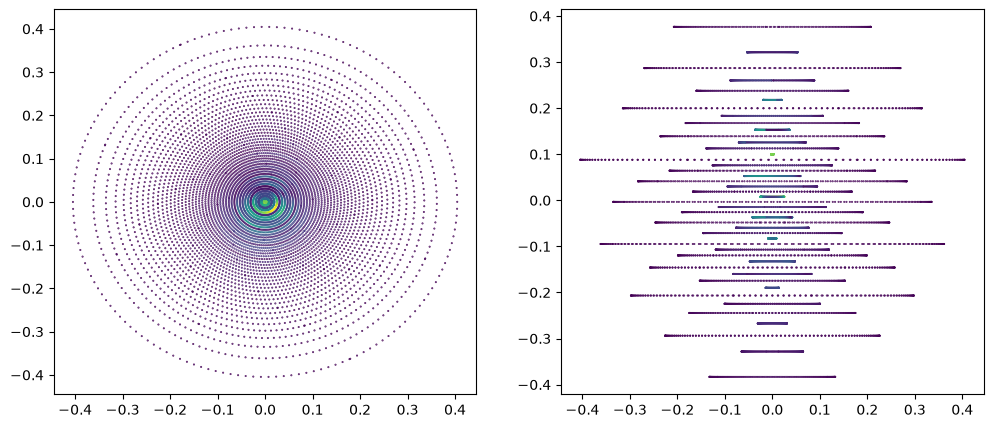

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

data_path = Path("test_data")
resolution = (64, 64, 8)

trajectory = np.load(data_path / "traj.npy")
data = np.load(data_path / "data.npy")
noise_cov = np.load(data_path / "noise_cov.npy")

print(trajectory.shape)
print(data.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(trajectory[:, 0], trajectory[:, 1], s=0.2, c=np.abs(data[0, :]))
axes[1].scatter(trajectory[:, 0], trajectory[:, 2], s=0.2, c=np.abs(data[0, :]))
plt.show()

In [5]:
from morse_pi import morse_pi

sens = morse_pi(
    data=data,
    trajectory=trajectory,
    resolution=resolution,
    backend="torchkbnufft-cpu",
    noise_cov=noise_cov,
    noise_whiten=True,
    noise_colour_power=2,
)

/Users/wclarke/Documents/Python/morse_pi/.pixi/envs/default/lib/python3.14/site-packages/mrinufft/_utils.py:67: UserWarning: Samples will be rescaled to [-pi, pi), assuming they were in [-0.5, 0.5)
  warnings.warn(
100%|██████████| 10/10 [00:06<00:00,  1.57it/s]


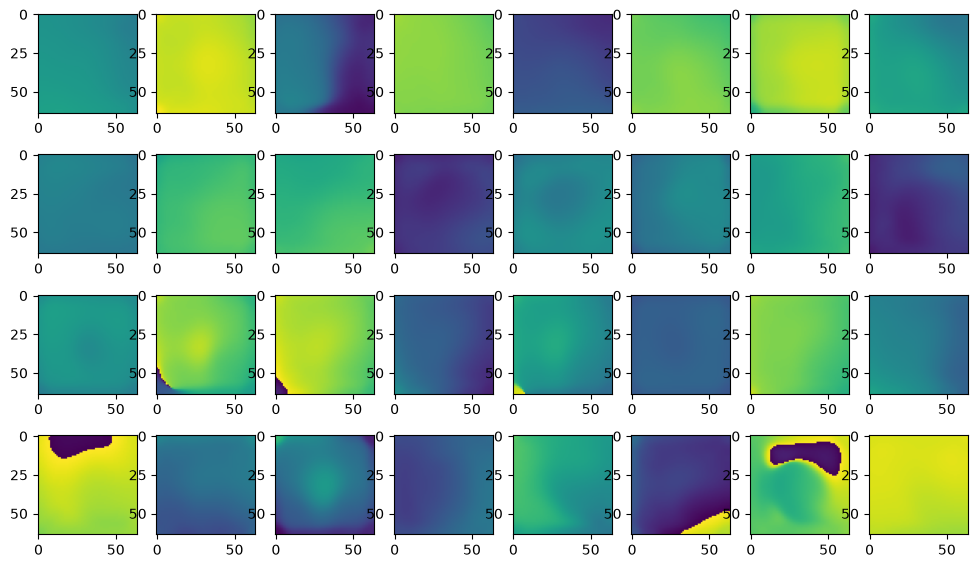

In [6]:
ref_dx = 0
slicedx = int(resolution[-1] / 2)
_, axes = plt.subplots(4, 8, figsize=(12, 7))
for idx, ax in enumerate(axes.ravel()):
    ax.imshow(np.abs(sens[..., slicedx, idx, ref_dx]))
    ax.imshow(np.angle(sens[..., slicedx, idx, ref_dx]), vmin=-np.pi, vmax=np.pi)

plt.show()